In [1]:
!pip install -q scikit-learn pandas matplotlib

In [2]:
documents = [
    "Python is useful for data analysis and automation.",
    "Data analysis often uses tables, statistics, and visual reports.",
    "Basketball teams practice shooting, passing, and defensive skills.",
    "Healthy meals can include vegetables, fruits, grains, and protein.",
    "Automation can reduce repetitive work in software projects.",
]

for number, document in enumerate(documents, start=1):
    print(f"Document {number}: {document}")

Document 1: Python is useful for data analysis and automation.
Document 2: Data analysis often uses tables, statistics, and visual reports.
Document 3: Basketball teams practice shooting, passing, and defensive skills.
Document 4: Healthy meals can include vegetables, fruits, grains, and protein.
Document 5: Automation can reduce repetitive work in software projects.


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = vectorizer.fit_transform(documents)

print("Matrix shape:", tfidf_matrix.shape)
print("Number of features:", len(vectorizer.get_feature_names_out()))

Matrix shape: (5, 29)
Number of features: 29


In [4]:
terms = vectorizer.get_feature_names_out()

for i, document in enumerate(documents):
    row = tfidf_matrix[i].toarray().ravel()
    top_indices = row.argsort()[::-1][:4]
    print(f"\nDocument {i+1}")
    for idx in top_indices:
        if row[idx] > 0:
            print(f"  {terms[idx]} -> {row[idx]:.3f}")


Document 1
  useful -> 0.503
  python -> 0.503
  automation -> 0.406
  data -> 0.406

Document 2
  visual -> 0.398
  uses -> 0.398
  reports -> 0.398
  statistics -> 0.398

Document 3
  teams -> 0.378
  skills -> 0.378
  shooting -> 0.378
  practice -> 0.378

Document 4
  vegetables -> 0.378
  healthy -> 0.378
  meals -> 0.378
  include -> 0.378

Document 5
  work -> 0.421
  repetitive -> 0.421
  software -> 0.421
  projects -> 0.421


In [5]:
tfidf_table = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=terms,
    index=[f"Document {i}" for i in range(1, len(documents) + 1)]
)

tfidf_table.round(2)

,analysis,automation,basketball,data,defensive,fruits,grains,healthy,include,meals,...,skills,software,statistics,tables,teams,useful,uses,vegetables,visual,work
Document 1,0.41,0.41,0.00,0.41,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.0,0.0,0.00,0.5,0.0,0.00,0.0,0.00
Document 2,0.32,0.00,0.00,0.32,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.4,0.4,0.00,0.0,0.4,0.00,0.4,0.00
Document 3,0.00,0.00,0.38,0.00,0.38,0.00,0.00,0.00,0.00,0.00,...,0.38,0.00,0.0,0.0,0.38,0.0,0.0,0.00,0.0,0.00
Document 4,0.00,0.00,0.00,0.00,0.00,0.38,0.38,0.38,0.38,0.38,...,0.00,0.00,0.0,0.0,0.00,0.0,0.0,0.38,0.0,0.00
Document 5,0.00,0.34,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.42,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.42


In [6]:
query = "software automation work"
query_vector = vectorizer.transform([query])

# Dot product measures weighted feature overlap.
scores = (tfidf_matrix @ query_vector.T).toarray().ravel()
ranking = scores.argsort()[::-1]

print("Query:", query)
print("\nRanked documents:")
for rank, idx in enumerate(ranking, start=1):
    print(f"{rank}. Score={scores[idx]:.3f} | {documents[idx]}")

Query: software automation work

Ranked documents:
1. Score=0.685 | Automation can reduce repetitive work in software projects.
2. Score=0.201 | Python is useful for data analysis and automation.
3. Score=0.000 | Healthy meals can include vegetables, fruits, grains, and protein.
4. Score=0.000 | Basketball teams practice shooting, passing, and defensive skills.
5. Score=0.000 | Data analysis often uses tables, statistics, and visual reports.


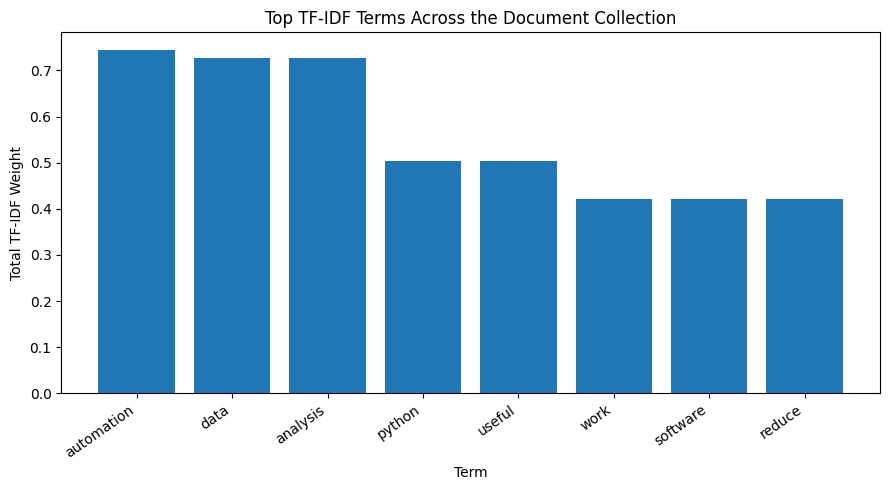

In [7]:
import matplotlib.pyplot as plt

total_weights = tfidf_matrix.sum(axis=0).A1
top = total_weights.argsort()[::-1][:8]

plt.figure(figsize=(9, 5))
plt.bar(terms[top], total_weights[top])
plt.xticks(rotation=35, ha="right")
plt.title("Top TF-IDF Terms Across the Document Collection")
plt.xlabel("Term")
plt.ylabel("Total TF-IDF Weight")
plt.tight_layout()
plt.show()